<div style="display: flex; justify-content: flex-start; align-items: center;">
    <a href="https://colab.research.google.com/github/msfasha/307307-BI-Methods-Generative-AI/blob/main/20261/Module%206%20-%20Introduction%20to%20CrewAI/CrewAI_Intro_lab.ipynb" target="_blank">
        <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" style="height: 25px;">
    </a>
</div>

<div style="background-color:#F5EDF4; border-top:3px solid #A83296; padding:16px; border-radius:6px">
<h1 style="color:#493347; margin:0">Lab: Building AI Teams with CrewAI</h1>
<p style="color:#56616D; margin:6px 0 0 0">307307 BI Methods for Generative AI - University of Petra</p>
</div>

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Objectives</h2>
</div>

By the end of this lab you will be able to:

1. Explain CrewAI in one sentence: a team of AI specialists, each with a role, working on tasks.
2. Build a working team in a few lines of Python.
3. Add, one step at a time: tools, several agents, a knowledge base, quality checks and a fixed workflow.
4. Compare what each addition costs (tokens) and what it buys (accuracy, control).

**How to use this notebook.** Run the cells from top to bottom. Each step changes the example only a little, so you always know what is new. Cells marked **Exercise** have a `# YOUR CODE HERE` area, with a worked solution in the comments below it.

**Prerequisite.** Do `CrewAI_Basics_lab.ipynb` first. It introduces Agent, Task, Crew, Process and Tool on a small example. This lab builds a larger, realistic one.

**You do not need to be good at Python.** Most of the work is writing clear sentences in plain English (a role, a goal, a task description).

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Background: the idea behind CrewAI</h2>
</div>

### The running example

Throughout the lab we work for **Petra Bean**, a small (fictional) neighbourhood coffee shop. The owner is thinking about selling **bottled cold brew coffee** and asks: *should we launch it?*

We start with one AI assistant giving a quick opinion, and finish with a small AI team that reads sales data, checks market notes, respects the shop's rules, remembers earlier decisions and writes a recommendation memo. The question stays the same; the team gets better at answering it.

<p align="center">
  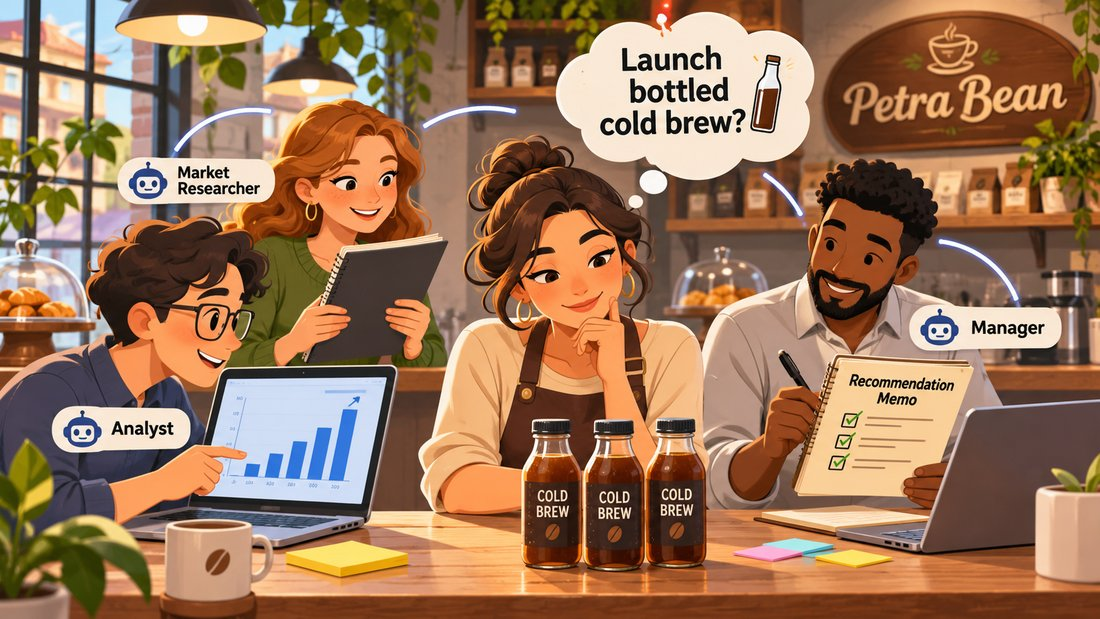
</p>

<p align="center"><em>The Petra Bean team: a market researcher, an analyst and a manager, working together on one question.</em></p>

### The building blocks

Think of how a small company answers a question like this. One person does not do everything: an analyst checks the numbers, a researcher reads the market, a manager writes the recommendation. CrewAI lets you build exactly that.

| CrewAI building block | Everyday analogy | One-line meaning |
|---|---|---|
| **Agent** | An employee | A role, a goal and a backstory that shape how the LLM behaves |
| **Task** | A job ticket | What to do, and what a good result looks like (`expected_output`) |
| **Crew** | The team | Agents plus tasks, run together |
| **Process** | How the team works | `sequential` (an assembly line) or `hierarchical` (a manager hands out work; not used in this lab) |
| **Tool** | A calculator or database | A Python function an agent can call to get real facts |
| **Knowledge** | The company handbook | Documents the team can look things up in (read-only) |
| **Guardrail** | A reviewer's checklist | A check a result must pass before the team moves on |
| **Flow** | The project plan | Ordinary, predictable steps that decide when to call a crew |

### Three ideas to remember

1. **Specialists beat one do-everything prompt.** A narrow role and goal makes answers more focused.
2. **You describe the work; the framework runs the loop.** Inside every agent, CrewAI runs the Thought, Action, Observation loop (ReAct) from Module 5. `verbose=True` lets you watch it.
3. **Autonomy and control are a dial.** A *crew* decides how to work; a *flow* follows steps you fixed. Real systems usually need both.

CrewAI saves you from writing the plumbing, but it also hides it. When an answer is wrong, what you learned in Modules 1 to 5 helps you see why. Keep `verbose=True` on while you learn.

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Setup</h2>
</div>

We install CrewAI (with Gemini support), then give it your Gemini API key. In Google Colab, store the key under the name `GOOGLE_API_KEY` in the Secrets panel (the key icon on the left). Anywhere else, the cell asks you to paste it.

The install takes one to two minutes. If Colab asks you to restart the session, do so and run the cell again.

In [ ]:
# Install CrewAI with Gemini support, plus pandas and matplotlib for data and charts.
# (Lines starting with "!" are shell commands. Remove the "!" if you run this in a terminal.)
!pip install -q "crewai[google-genai]" pandas matplotlib

In [ ]:
import os, getpass
from dotenv import load_dotenv, find_dotenv

# If you keep your keys in a .env file (local use), load them. On Colab there is no .env, so this does nothing.
load_dotenv(find_dotenv(usecwd=True))

# Read the API key from Colab Secrets if available, otherwise ask for it.
try:
    from google.colab import userdata
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
except Exception:
    if not os.environ.get("GOOGLE_API_KEY"):
        os.environ["GOOGLE_API_KEY"] = getpass.getpass("Paste your Gemini API key: ")

# Turn off anonymous usage reporting so nothing from this lab leaves your session.
os.environ["OTEL_SDK_DISABLED"] = "true"
os.environ["CREWAI_TRACING_ENABLED"] = "false"

print("API key loaded:", bool(os.environ.get("GOOGLE_API_KEY")))

### Choose the model

The prefix `gemini/` tells CrewAI to use Google Gemini. If you later see a "model not found" error, change only the `MODEL` line (see the model list in Google AI Studio).

Two more settings:

- `MAX_RPM` limits requests per minute. Free keys have limits and a team makes many calls, so a few short pauses are normal.
- `EMBEDDER` is the model that turns text into numbers for the knowledge base (Step 5). An error mentioning `OPENAI_API_KEY` means this setting was not passed.

In [ ]:
from crewai import LLM

MODEL = "gemini/gemini-3.8-flash"   # change this line if your key cannot see this model
MAX_RPM = 8                         # requests per minute (keeps free keys from being rate limited)
EMBEDDER = {
    "provider": "google-generativeai",
    "config": {"model_name": "gemini-embedding-001"},
}

llm = LLM(model=MODEL)

# Quick test: one direct question to the model, no agents yet.
print(llm.call("Say hello to a coffee shop owner in one short sentence."))

### Load the example data

Petra Bean has three small files. All numbers are made up for teaching.

- `sales.csv`: twelve months of sales for five products.
- `market_notes.txt`: notes from a neighbourhood survey, plus competitor prices and supplier quotes.
- The owner's handbook (a few house rules). It is a short text in the next cell, and we use it as a knowledge base in Step 5.

The first two files live next to this notebook in the course repository. The cell below downloads them if they are not already in your session.

In [ ]:
import os, urllib.request
import pandas as pd

BASE = ("https://raw.githubusercontent.com/msfasha/307307-BI-Methods-Generative-AI/main/"
        "20261/Module%206%20-%20Introduction%20to%20CrewAI/")

# Download the data files if they are not already here.
for name in ["sales.csv", "market_notes.txt"]:
    if not os.path.exists(name):
        urllib.request.urlretrieve(BASE + name, name)

sales = pd.read_csv("sales.csv")
sales.head(6)

In [ ]:
# The owner's handbook: house rules the team must respect (used in Step 5).
HANDBOOK = '''PETRA BEAN OWNER HANDBOOK

Investment rule: any new product may use at most 2,500 of up-front investment without a bank loan.
Payback rule: a new product must pay back its investment within 6 months of launch.
Packaging rule: all packaging must be recyclable. No single-use plastic.
Launch rule: new products are first piloted at the main shop only, never at all locations at once.
Quality rule: we never sell a drink that is more than 7 days old.
'''

print(open("market_notes.txt").read())

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Step 1: One agent, one task</h2>
</div>

The smallest possible team: **one agent** and **one task**.

- The **Agent** has a `role`, a `goal` and a `backstory`. These three sentences become the instructions the LLM receives, so write them like a job description.
- The **Task** has a `description` (what to do) and an `expected_output` (what a good answer looks like). Anything in curly braces, such as `{idea}`, is filled in when the crew starts.
- The **Crew** runs the agent on the task. `kickoff_async()` starts the run. In a notebook we write `await crew.kickoff_async(...)`; in an ordinary Python script you would write `crew.kickoff(...)`.

Read the printed output: you will see the agent's *Thought* and its *Final Answer*. This is the ReAct loop from Module 5, run for you.

In [ ]:
from crewai import Agent, Task, Crew

# The agent: a role, a goal and a backstory (like a job description).
analyst_basic = Agent(
    role="Cafe Business Analyst",
    goal="Give small cafe owners clear and honest first opinions on new product ideas",
    backstory=(
        "You have ten years of experience advising independent coffee shops. "
        "You are practical, you like numbers, and you say clearly when something is uncertain."
    ),
    llm=llm,
    verbose=True,          # print the agent's thinking so we can learn from it
)

# The task: what to do, and what a good answer looks like.
first_task = Task(
    description=(
        "The owner of Petra Bean, a small neighbourhood coffee shop, is thinking about selling {idea}. "
        "Give a short first opinion: is it promising, and what should we check first?"
    ),
    expected_output="A short answer of at most 120 words.",
    agent=analyst_basic,
)

# The crew: the team, ready to run.
crew1 = Crew(agents=[analyst_basic], tasks=[first_task], verbose=True, max_rpm=MAX_RPM)

result1 = await crew1.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})

In [ ]:
# The final answer is stored in result1.raw
print(result1.raw)

# token_usage shows how much "text" the run consumed. Tokens are what you pay for.
print(result1.token_usage)

# We will keep a small scoreboard of tokens per step, to compare costs at the end.
usage = {"1. One agent": result1.token_usage.total_tokens}

**What to notice.** The answer sounds confident, but the agent has seen none of our data. Its numbers (if any) are guesses. Fixing that is the point of the next steps.

### Exercise 1: change the personality

Create a second agent called `accountant` with a cautious, numbers-first personality, give it the same task, and compare its answer with the analyst's. Reuse `first_task` by creating a new task object (a task remembers its last answer, so each agent needs its own).

In [ ]:
# YOUR CODE HERE



# ---- Solution (remove the # signs to try it) ----
# accountant = Agent(
#     role="Cautious Accountant",
#     goal="Protect the owner's money by questioning every new spending idea",
#     backstory="You have seen many small businesses fail by launching too fast. You always ask what could go wrong.",
#     llm=llm,
#     verbose=True,
# )
# task_acc = Task(
#     description=first_task.description,
#     expected_output=first_task.expected_output,
#     agent=accountant,
# )
# crew_acc = Crew(agents=[accountant], tasks=[task_acc], max_rpm=MAX_RPM)
# print((await crew_acc.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})).raw)

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Step 2: Make the answer predictable (structured output)</h2>
</div>

Free text is hard to use in a business process. If a later step needs the verdict ("go", "maybe" or "no-go"), we want it as a **field**, not buried in a paragraph.

We describe the shape of the answer with a small Python class (a *Pydantic model*), and give it to the task as `output_pydantic`. CrewAI then makes sure the answer fits that shape.

This is also a governance habit: a fixed format is easy to check, log and audit.

In [ ]:
from typing import List, Literal
from pydantic import BaseModel

# The shape of the answer we want back.
class QuickVerdict(BaseModel):
    verdict: Literal["go", "maybe", "no-go"]   # only these three values are allowed
    reasons: List[str]
    risks: List[str]

def build_verdict_task():
    # A function that returns a fresh task each time (a task remembers its last answer).
    return Task(
        description=(
            "The owner of Petra Bean is thinking about selling {idea}. "
            "Give a first verdict (go, maybe or no-go), the main reasons, and the main risks."
        ),
        expected_output="A verdict with a short list of reasons and a short list of risks.",
        agent=analyst_basic,
        output_pydantic=QuickVerdict,     # NEW in this step
    )

crew2 = Crew(agents=[analyst_basic], tasks=[build_verdict_task()], max_rpm=MAX_RPM)
result2 = await crew2.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})

# Now we can use the answer like data, not just text.
v = result2.pydantic
print("Verdict:", v.verdict)
print("Reasons:", v.reasons)
print("Risks:  ", v.risks)

usage["2. Structured output"] = result2.token_usage.total_tokens

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Step 3: Give the agent tools</h2>
</div>

Language models are fluent but not reliable with facts and arithmetic. A **tool** is an ordinary Python function the agent may call. The agent reads the tool's name and its description (the text in triple quotes), decides when to use it, and receives the result back as an *Observation*.

We build three tools:

1. `sales_summary`: reads our real `sales.csv` and reports totals for one product.
2. `margin_calculator`: does the profit and payback arithmetic exactly.
3. `market_notes_reader`: returns the market notes file.

**The description matters.** It is the only thing the agent knows about the tool. Write it for a new employee.

First, a quick experiment: ask an agent *without* tools for a number from our data. It cannot know it.

In [ ]:
# Experiment: no tools, so any number it gives us is invented.
test_agent = Agent(
    role="Cafe Data Analyst",
    goal="Answer questions about Petra Bean's sales",
    backstory="You analyse sales for a small coffee shop.",
    llm=llm,
)
test_task = Task(
    description="How many Iced Lattes did Petra Bean sell in July?",
    expected_output="One number, and one sentence explaining where it comes from.",
    agent=test_agent,
)
guess = await Crew(agents=[test_agent], tasks=[test_task], max_rpm=MAX_RPM).kickoff_async()
print("Agent without tools says:", guess.raw)

# The true answer, computed directly from the data:
true_value = int(sales[(sales["product"] == "Iced Latte") & (sales["month"] == "Jul")]["units"].iloc[0])
print("True value in sales.csv:  ", true_value)

In [ ]:
from crewai.tools import tool

@tool("Sales summary")
def sales_summary(product: str) -> str:
    """Summarise twelve months of sales for ONE product from the cafe's sales file.
    The product must be one of: Espresso, Latte, Hot Tea, Iced Latte, Pastry.
    Returns total units, revenue, gross profit, and the best and worst month."""
    df = pd.read_csv("sales.csv")
    d = df[df["product"].str.lower() == product.strip().lower()]
    if d.empty:
        return f"Unknown product '{product}'. Use one of: {', '.join(df['product'].unique())}."
    d = d.assign(revenue=d["units"] * d["price"], profit=d["units"] * (d["price"] - d["unit_cost"]))
    best = d.loc[d["units"].idxmax()]
    worst = d.loc[d["units"].idxmin()]
    monthly = ", ".join(f"{m}:{u}" for m, u in zip(d["month"], d["units"]))
    return (
        f"{product}: total units {int(d['units'].sum())}, revenue {d['revenue'].sum():.0f}, "
        f"gross profit {d['profit'].sum():.0f}. "
        f"Best month {best['month']} ({int(best['units'])} units), worst month {worst['month']} ({int(worst['units'])} units). "
        f"Monthly units -> {monthly}"
    )

@tool("Margin calculator")
def margin_calculator(price: float, unit_cost: float, units_per_month: int, up_front_investment: float) -> str:
    """Calculate profit per unit, monthly profit and payback time in months for a new product.
    Inputs: selling price per unit, cost per unit, expected units sold per month,
    and the one-off up-front investment. Use this for any profit or payback arithmetic."""
    profit_per_unit = price - unit_cost
    monthly_profit = profit_per_unit * units_per_month
    payback = up_front_investment / monthly_profit if monthly_profit > 0 else float("inf")
    return (
        f"Profit per unit {profit_per_unit:.2f}; monthly profit {monthly_profit:.2f}; "
        f"payback time {payback:.1f} months."
    )

@tool("Market notes reader")
def market_notes_reader(topic: str = "all") -> str:
    """Return the cafe's market notes: survey results, competitor prices, supplier costs and search trends.
    The 'topic' argument is optional and can be left as 'all'."""
    with open("market_notes.txt") as f:
        return f.read()

# Try the tools directly first, like a normal function. (They work without any AI.)
print(sales_summary.run(product="Iced Latte"))
print(margin_calculator.run(price=4.5, unit_cost=1.1, units_per_month=300, up_front_investment=1800))

Now give the tools to an agent. Notice how little changes: one new argument, `tools=[...]`. Watch the printed log: each time the agent uses a tool you will see the tool's name (CrewAI writes it in lower case with underscores, for example `sales_summary`), what the agent sent to it, and what came back. That pair is an Action followed by an Observation.

In [ ]:
analyst = Agent(
    role="Cafe Data Analyst",
    goal="Answer questions about Petra Bean's sales and profits using the real data",
    backstory="You analyse sales for a small coffee shop. You never guess a number you can look up or calculate.",
    llm=llm,
    tools=[sales_summary, margin_calculator],     # NEW in this step
    verbose=True,
)
tool_task = Task(
    description="How many Iced Lattes did Petra Bean sell in July? Use the sales tool.",
    expected_output="One number, and one sentence explaining where it comes from.",
    agent=analyst,
)
result3 = await Crew(agents=[analyst], tasks=[tool_task], max_rpm=MAX_RPM, verbose=True).kickoff_async()
print("Agent with tools says:", result3.raw)
print("True value:           ", true_value)
usage["3. Tools"] = result3.token_usage.total_tokens

### Exercise 2: write your own tool

Write a tool called `break_even_units` that takes `fixed_cost`, `price` and `unit_cost` and returns how many units must be sold to recover the fixed cost. Test it directly with `.run(...)` as we did above. (Check your answer by hand: 1,800 / (4.50 - 1.10) is about 530 units.)

In [ ]:
# YOUR CODE HERE



# ---- Solution (remove the # signs to try it) ----
# @tool("Break-even units")
# def break_even_units(fixed_cost: float, price: float, unit_cost: float) -> str:
#     """Calculate how many units must be sold to recover a one-off fixed cost.
#     Inputs: fixed cost, selling price per unit, cost per unit."""
#     margin = price - unit_cost
#     if margin <= 0:
#         return "The price is not higher than the cost, so the fixed cost can never be recovered."
#     return f"Break-even after {fixed_cost / margin:.0f} units."
#
# print(break_even_units.run(fixed_cost=1800, price=4.5, unit_cost=1.1))

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Step 4: A team of agents (sequential process)</h2>
</div>

One agent with tools is useful. A **team** is better when jobs need different skills. We now build three specialists:

<p align="center">
  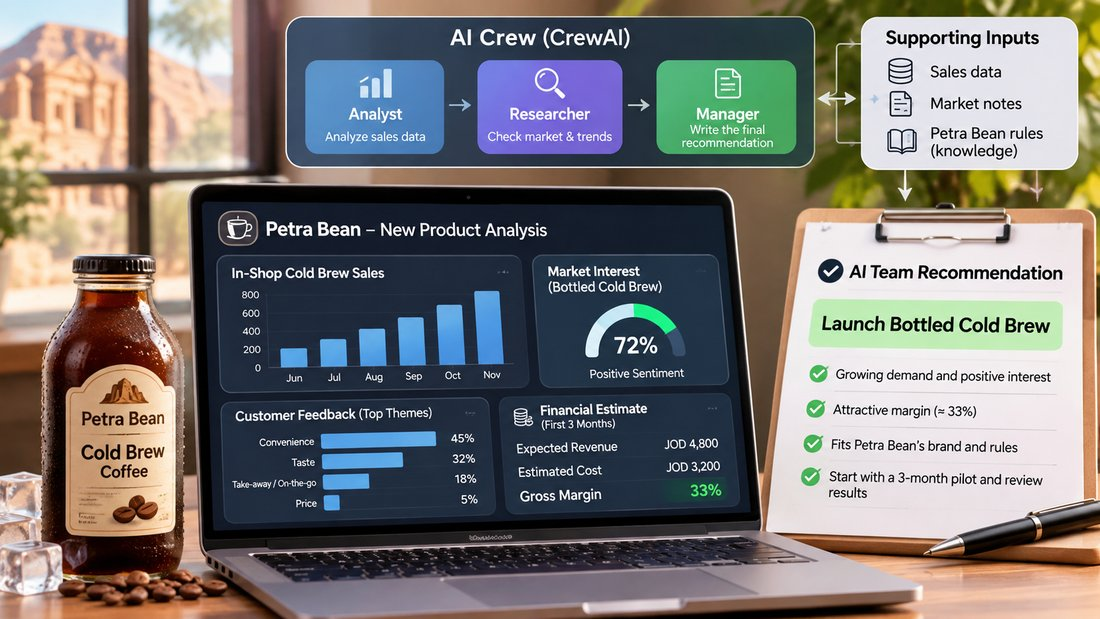
</p>

<p align="center"><em>The idea of this part: specialists work in turn, using the shop's data and rules, and end with a recommendation. The numbers in this illustration are invented; your run will produce its own.</em></p>

| Agent | Job | Tools |
|---|---|---|
| Data Analyst | Facts from our own sales and the profit arithmetic | `sales_summary`, `margin_calculator` |
| Market Researcher | Customer demand, competitors and costs | `market_notes_reader` |
| Strategy Writer | Turns the findings into a recommendation memo | none |

They work in a **sequential process**: task 1, then task 2, then task 3, like an assembly line. The memo task uses `context=[...]` to receive the results of the two earlier tasks. The finished memo is also saved to a file with `output_file`.

We put the tasks inside a function, `build_tasks()`, because a task remembers its last answer; this way each step of the lab starts from fresh tasks.

In [ ]:
from crewai import Process

researcher = Agent(
    role="Market Researcher",
    goal="Find what customers want, what competitors charge, and what a new product would cost",
    backstory="You turn survey notes and supplier quotes into clear facts. You only report what the notes say.",
    llm=llm,
    tools=[market_notes_reader],
    verbose=True,
)

writer = Agent(
    role="Strategy Writer",
    goal="Write a clear, honest one-page recommendation for a busy cafe owner",
    backstory="You write for owners, not for experts. You state a clear recommendation, give the numbers behind it, and name the risks.",
    llm=llm,
    tools=[margin_calculator],     # the writer may calculate profit and payback
    verbose=True,
)

def build_tasks(memo_guardrail=None, human_review=False):
    t_sales = Task(
        description=(
            "Analyse Petra Bean's sales data to judge how strong cold and iced drinks are. "
            "Use the sales tool for Iced Latte and Latte. Report the numbers, and how much higher summer sales are than winter."
        ),
        expected_output="Five bullet points with the key sales facts and numbers.",
        agent=analyst,
    )
    t_market = Task(
        description="Read the market notes about {idea}. Summarise demand, competitor prices, costs and trends.",
        expected_output="Five bullet points with the key market facts and numbers.",
        agent=researcher,
    )
    t_memo = Task(
        description=(
            "Write a one-page recommendation memo on whether Petra Bean should launch {idea}. "
            "Use the findings from the analyst and the researcher. "
            "Use the margin calculator to compute profit per bottle and payback time, assuming a price of 4.50, "
            "a cost of 1.10 per bottle, 300 bottles per month and an up-front investment of 1,800."
        ),
        expected_output=(
            "A memo in markdown with the sections: Recommendation, Evidence, Payback, Risks, Next steps."
        ),
        agent=writer,
        context=[t_sales, t_market],        # receives the results of the two earlier tasks
        output_file="cold_brew_memo.md",    # the memo is also saved to this file
        guardrail=memo_guardrail,
        human_input=human_review,
    )
    return [t_sales, t_market, t_memo]

crew4 = Crew(
    agents=[analyst, researcher, writer],
    tasks=build_tasks(),
    process=Process.sequential,         # one task after the other
    verbose=True,
    max_rpm=MAX_RPM,
)
result4 = await crew4.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})

In [ ]:
from IPython.display import Markdown

# Show the final memo nicely formatted.
display(Markdown(result4.raw))
usage["4. Team (sequential)"] = result4.token_usage.total_tokens
print("Tokens used:", result4.token_usage.total_tokens)

**What to notice.** Compare this memo with the Step 1 answer. The numbers now come from tools, and each agent stayed inside its role. The cost: far more tokens, because three agents each ran their own thinking loop.

### Exercise 3: add a reviewer

Add a fourth agent, a **Risk Reviewer**, who reads the memo and lists the three biggest risks it missed. Add one more task for the reviewer and put both in a new crew.

Hint: the reviewer's task needs `context=[...]` pointing at the memo task. Because the memo task is created inside `build_tasks()`, you can use `tasks = build_tasks()` and then refer to `tasks[2]`.

In [ ]:
# YOUR CODE HERE



# ---- Solution (remove the # signs to try it) ----
# reviewer = Agent(
#     role="Risk Reviewer",
#     goal="Find the weaknesses in a recommendation before the owner acts on it",
#     backstory="You are a sceptical advisor. You look for risks that the author overlooked.",
#     llm=llm,
#     verbose=True,
# )
# tasks = build_tasks()
# t_review = Task(
#     description="Read the memo and list the three biggest risks it missed or understated.",
#     expected_output="Three numbered risks, each with one sentence of explanation.",
#     agent=reviewer,
#     context=[tasks[2]],
# )
# crew_ex3 = Crew(agents=[analyst, researcher, writer, reviewer], tasks=tasks + [t_review],
#                 process=Process.sequential, max_rpm=MAX_RPM)
# print((await crew_ex3.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})).raw)

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Step 5: Knowledge, the company handbook</h2>
</div>

Our memo ignored the owner's rules. A real analyst would know the handbook. We give the crew a **knowledge base**: documents it can search before answering.

Behind the scenes this is the RAG idea from Module 3: the text is split into chunks, each chunk is turned into an embedding, and the most relevant chunks are retrieved when an agent needs them.

- **Knowledge** = facts *you* provide up front. Read-only. (CrewAI also has a *Memory* feature for things a team learns while working; see the docs.)

We pass `knowledge_sources` and the embedder to the crew. Nothing else changes.

In [ ]:
from crewai.knowledge.source.string_knowledge_source import StringKnowledgeSource

handbook_source = StringKnowledgeSource(content=HANDBOOK)

crew5 = Crew(
    agents=[analyst, researcher, writer],
    tasks=build_tasks(),
    process=Process.sequential,
    knowledge_sources=[handbook_source],     # NEW in this step
    embedder=EMBEDDER,                       # NEW in this step
    verbose=True,
    max_rpm=MAX_RPM,
)
result5 = await crew5.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})
display(Markdown(result5.raw))
usage["5. + Knowledge"] = result5.token_usage.total_tokens

**Check your reading.** Does the new memo mention the 2,500 investment limit, the 6-month payback rule, recyclable packaging or the main-shop-first pilot? Which rules did the memo use, and which did it ignore? Knowledge makes rules *available*; it does not force the agent to use them. That is what guardrails (Step 6) are for.

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Step 6: Quality and control (guardrails and human review)</h2>
</div>

Agents can skip sections, ignore rules or drift off topic. Two simple controls:

- A **guardrail** is a Python function that checks a task's output. If the check fails, the message you return is sent back to the agent, which tries again (up to `guardrail_max_retries` times).
- **Human input** (`human_input=True`) pauses the crew and asks a person to approve or give feedback before the task is finished. This is human-in-the-loop in its simplest form.

Our guardrail is deliberately plain: the memo must contain the words *Recommendation*, *Risks* and *Payback*, and must mention the 2,500 investment limit.

If the agent still fails the check after its allowed retries, CrewAI stops with an error such as *Task failed guardrail validation*. That is the guardrail doing its job: a bad result is blocked instead of passed along. In a real system you would catch this error and send the case to a person.

In [ ]:
def memo_guardrail(output):
    # 'output.raw' is the agent's text. Return (True, output) to accept it,
    # or (False, "message") to send it back for another try.
    text = output.raw.lower().replace(",", "")      # so "2,500" and "2500" both count
    required = ["recommendation", "risks", "payback", "2500"]
    missing = [word for word in required if word not in text]
    if missing:
        return (False, f"The memo is missing: {missing}. Add these and check against the owner's handbook.")
    return (True, output)

HUMAN_REVIEW = False    # set to True to be asked for approval before the memo is final

tasks7 = build_tasks(memo_guardrail=memo_guardrail, human_review=HUMAN_REVIEW)
tasks7[2].guardrail_max_retries = 2        # try at most two corrections

crew7 = Crew(
    agents=[analyst, researcher, writer],
    tasks=tasks7,
    process=Process.sequential,
    knowledge_sources=[handbook_source],
    embedder=EMBEDDER,
    verbose=True,
    max_rpm=MAX_RPM,
)
result7 = await crew7.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})
display(Markdown(result7.raw))
usage["6. + Guardrail"] = result7.token_usage.total_tokens

### Exercise 4: write your own rule

Add a second guardrail that rejects a memo longer than 400 words, then ask the team again. Think about why a business might want a limit like this.

In [ ]:
# YOUR CODE HERE



# ---- Solution (remove the # signs to try it) ----
# def length_guardrail(output):
#     words = len(output.raw.split())
#     if words > 400:
#         return (False, f"The memo has {words} words. Shorten it to at most 400 words.")
#     return (True, output)
#
# tasks_ex4 = build_tasks(memo_guardrail=length_guardrail)
# crew_ex4 = Crew(agents=[analyst, researcher, writer], tasks=tasks_ex4, process=Process.sequential, max_rpm=MAX_RPM)
# out = await crew_ex4.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})
# print(len(out.raw.split()), "words")

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Step 7: Put the crew inside a Flow</h2>
</div>

A crew is autonomous. But businesses also need **fixed rules**: do a cheap check first, stop early if the answer is clearly no, and only then spend money on the full team.

A **Flow** is ordinary, predictable code that decides when to run crews:

- `@start()` marks the first step.
- `@listen(step)` runs after another step.
- `@router(step)` returns a label ("continue" or "stop") that chooses the next path.
- `self.state` is shared notes the steps can read and write.

Our flow: quick one-agent verdict (Step 2) → if the verdict is "no-go", stop; otherwise run the full team.

In [ ]:
from crewai.flow.flow import Flow, start, listen, router

class LaunchState(BaseModel):
    idea: str = ""
    verdict: str = ""
    memo: str = ""

class LaunchFlow(Flow[LaunchState]):

    @start()
    async def quick_check(self):
        # Step A: the cheap, single-agent verdict.
        crew = Crew(agents=[analyst_basic], tasks=[build_verdict_task()], max_rpm=MAX_RPM)
        out = await crew.kickoff_async(inputs={"idea": self.state.idea})
        self.state.verdict = out.pydantic.verdict
        print("Quick verdict:", self.state.verdict)

    @router(quick_check)
    def decide(self):
        # Step B: ordinary Python decides the path. No AI involved here.
        return "stop" if self.state.verdict == "no-go" else "continue"

    @listen("continue")
    async def full_analysis(self):
        # Step C: only now do we pay for the full team.
        crew = Crew(
            agents=[analyst, researcher, writer],
            tasks=build_tasks(memo_guardrail=memo_guardrail),
            process=Process.sequential,
            knowledge_sources=[handbook_source],
            embedder=EMBEDDER,
            max_rpm=MAX_RPM,
        )
        out = await crew.kickoff_async(inputs={"idea": self.state.idea})
        self.state.memo = out.raw

    @listen("stop")
    def stop_early(self):
        self.state.memo = "Stopped early: the quick check said no-go, so no further analysis was paid for."

flow = LaunchFlow()
await flow.kickoff_async(inputs={"idea": "bottled cold brew coffee (330 ml)"})
display(Markdown(flow.state.memo))

**Try this.** Run the flow again with an idea that should fail the quick check, for example `"a drive-through window for a shop with no parking"`, and watch it stop early. A flow gives you a predictable skeleton and a way to control cost.

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Wrap-up: what did each step cost?</h2>
</div>

Every addition made the team more capable, and also used more tokens. Tokens cost money and time. Let us compare the steps we ran.

In [ ]:
import matplotlib.pyplot as plt

cost = pd.DataFrame({"step": list(usage.keys()), "total_tokens": list(usage.values())})
display(cost)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(cost["step"][::-1], cost["total_tokens"][::-1], color="#356B8C")
ax.set_xlabel("Total tokens used")
ax.set_title("Tokens used per step (more capable also means more expensive)")
plt.tight_layout()
plt.show()

**Reading the chart.** The jump from one agent to a team is the largest. Ask yourself: for which decisions is that extra cost justified? A coffee-shop launch memo? A monthly report? A customer chat that runs ten thousand times a day?

### Summary table

| Step | What we added | What it gave us | What it cost |
|---|---|---|---|
| 1 | Agent, task, crew | A first answer | Guesses, no real data |
| 2 | Structured output | An answer other code can use | Almost nothing |
| 3 | Tools | Real numbers, exact arithmetic | More tokens (tool loop) |
| 4 | Several agents | Division of labour, a memo | Many more tokens |
| 5 | Knowledge | Respect for house rules | Embedding calls |
| 6 | Guardrail, human review | Quality control, human oversight | Retries |
| 7 | Flow | Fixed rules and early stopping | Extra code to design |

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Capstone exercise: your own business</h2>
</div>

Pick a business you know (a bookshop, a gym, an online store, a family restaurant) and a decision it faces. Build a small crew that produces a recommendation.

Minimum requirements:

1. At least **two agents** with different roles and clearly written goals.
2. At least **one tool** that reads data you create (a small CSV or a text file) or does arithmetic.
3. A **structured output** or a **guardrail** that checks the final answer.
4. A short note (three sentences) explaining *where the team could be wrong* and who should review the result before anyone acts on it.

Bonus: add knowledge (a short policy text), or wrap the crew in a flow with an early-stop rule.

In [ ]:
# YOUR CODE HERE
# Step 1: create your data file (a few rows is enough).
# Step 2: write one tool that reads it.
# Step 3: define two or more agents with clear roles and goals.
# Step 4: define the tasks (use expected_output carefully).
# Step 5: run the crew with kickoff(), and read the verbose output.
# Step 6: write your three-sentence note on where the team could be wrong.

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Troubleshooting</h2>
</div>

| Message or symptom | Likely cause | What to do |
|---|---|---|
| `model not found` or a 404 | The model name is not available to your key | Change `MODEL` in the setup cell |
| `429` or `quota` or `rate limit` | Too many requests per minute on a free key | Wait a minute, lower `MAX_RPM`, run the cell again |
| Error mentioning `OPENAI_API_KEY` | CrewAI used its default embedder | Make sure `embedder=EMBEDDER` is passed to the crew |
| The agent ignores a tool | The tool description is vague | Rewrite the description in the triple quotes, name the inputs clearly |
| A task returns an old answer | A task object was reused | Create fresh tasks (we use `build_tasks()` for this) |
| `sales.csv` or `market_notes.txt` not found | The download cell did not run, or you have no internet | Run the data cell again, or upload both files next to the notebook |
| `503 UNAVAILABLE` or `high demand` | Google's servers for this model are busy (common on free keys) | Wait a minute and run the cell again, or change `MODEL` |
| `invoked synchronously from within a running event loop` | `kickoff()` was used inside a notebook | Use `await crew.kickoff_async(...)` |
| The run is slow | Several agents each make several model calls | This is normal; try a single agent first |

<div style="background-color:#F7F3F7; border-left:4px solid #C8ABC3; padding:10px; border-radius:4px; margin-top:14px">
<h2 style="color:#493347; margin:0">Summary</h2>
</div>

- CrewAI lets you describe a **team** (agents, tasks, process) instead of writing the agent loop yourself.
- **Tools** replace guessing with facts. **Knowledge** provides rules and reference text.
- **Structured output, guardrails and human review** make results checkable. These are the first practical tools of AI governance, which we study in the second half of the course.
- **Flows** put predictable steps around autonomous crews, and the **token chart** shows that more capability also costs more.

### Questions to take away

1. Which step changed the answer the most? Which changed the *cost* the most? Were they the same?
2. If the memo is wrong and the owner follows it, who is responsible: the owner, the person who built the crew, or the model provider?
3. Which of the seven steps would you remove for a real shop, and why?

### Further reading

- CrewAI documentation: https://docs.crewai.com
- Google AI Studio (API keys and model list): https://aistudio.google.com
- Course book: *An Illustrated Guide to AI Agents*